## Hierarchisch Clusteren

Clusteren = het verdelen van je dataset in verschillende groepen op basis van verschillende eigenschappen van je data.

We gaan data hierarchisch clusteren:<br>
[Hierarchical clustering](https://www.w3schools.com/python/python_ml_hierarchial_clustering.asp) is an unsupervised learning method for clustering data points. The algorithm builds clusters by measuring the dissimilarities between data. Unsupervised learning means that a model does not have to be trained, and we do not need a "target" variable. This method can be used on any data to visualize and interpret the relationship between individual data points.

We lezen eerst de benodigde libraries in.


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from scipy.cluster.hierarchy import dendrogram, linkage
from sklearn.cluster import AgglomerativeClustering

# Voorbeeld 1 Willekeurige data
Nu creeren we een dataset waarmee we het clusteren gaan oefenen.

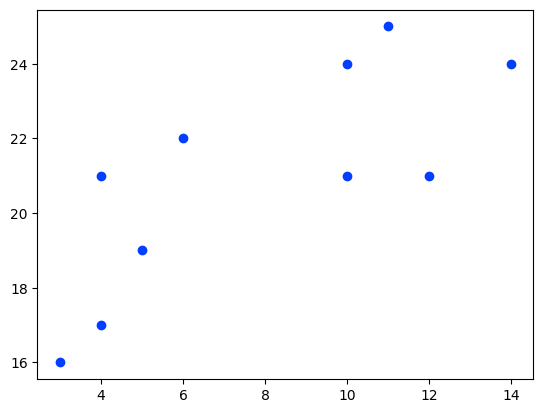

In [ ]:
x = [4, 5, 10, 4, 3, 11, 14 , 6, 10, 12]
y = [21, 19, 24, 17, 16, 25, 24, 22, 21, 21]

plt.scatter(x, y)
plt.show()

We zien dat er 2 clusters lijken te zijn.<br>
Het dendrogram bevestigt dat:

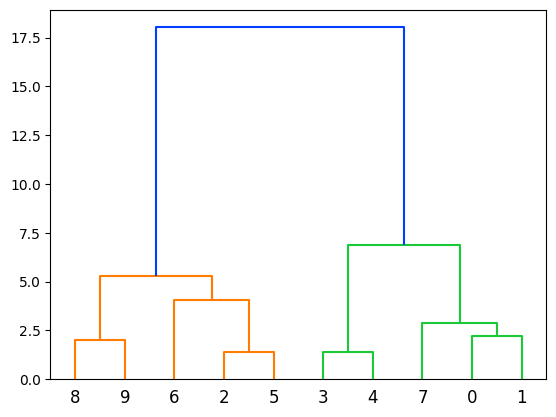

In [ ]:
data = list(zip(x, y))

linkage_data = linkage(data, method='ward', metric='euclidean')
dendrogram(linkage_data)

plt.show()

Hoe lees je dit fijne dendrogram af? <br>
Leg een potlood horizontaal over het plaatje bij een bepaalde afstand op de y-as (bijvoorbeeld 7,5) en tel hoeveel rechthoeken er DIRECT ONDER deze lijn zitten.
<p>
In bovenstaand plaatje: 2.<br>
Dat betekent dat er in ieder geval 2 clusters in de data zitten (als je als afstand tussen de clusters 7,5 of kleiner gebruikt).

We kunnen de clusters ook in kleur visualiseren:

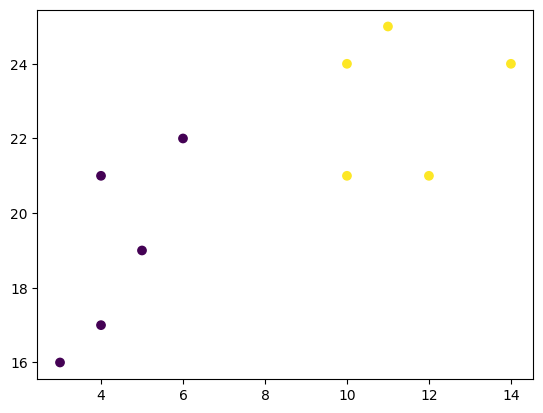

In [ ]:
data = list(zip(x, y))

hierarchical_cluster = AgglomerativeClustering(n_clusters=2, metric='euclidean', linkage='ward')
labels = hierarchical_cluster.fit_predict(data)

plt.scatter(x, y, c=labels)
plt.show()

Conclusie?

# Voorbeeld 2: Pinguins
Via panda's wordt het bestand penguins_size.csv ingelezen.

De NaN's worden uit de dataframe gehaald omdat er geen waarden zijn die ingevuld kunnen worden die een nuttige uitkomst geven.


In [ ]:
# =====================Inladen bestanden=======================================
# Tabellen met parameters ophalen uit dit bestand.
df = pd.read_csv("penguins_size.csv")
# =============================================================================
df = df.dropna()
df

,species,island,culmen_length_mm,culmen_depth_mm,flipper_length_mm,body_mass_g,sex
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,MALE
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,FEMALE
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,FEMALE
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,FEMALE
5,Adelie,Torgersen,39.3,20.6,190.0,3650.0,MALE
...,...,...,...,...,...,...,...
338,Gentoo,Biscoe,47.2,13.7,214.0,4925.0,FEMALE
340,Gentoo,Biscoe,46.8,14.3,215.0,4850.0,FEMALE
341,Gentoo,Biscoe,50.4,15.7,222.0,5750.0,MALE
342,Gentoo,Biscoe,45.2,14.8,212.0,5200.0,FEMALE


In [ ]:
df.describe()

,culmen_length_mm,culmen_depth_mm,flipper_length_mm,body_mass_g
count,334.000000,334.000000,334.000000,334.000000
mean,43.994311,17.160479,201.014970,4209.056886
std,5.460521,1.967909,14.022175,804.836129
min,32.100000,13.100000,172.000000,2700.000000
25%,39.500000,15.600000,190.000000,3550.000000
50%,44.500000,17.300000,197.000000,4050.000000
75%,48.575000,18.700000,213.000000,4793.750000
max,59.600000,21.500000,231.000000,6300.000000


In onderstaand scatterplot wordt de lengte en 'diepte' van de snavel tegen elkaar uitgezet.

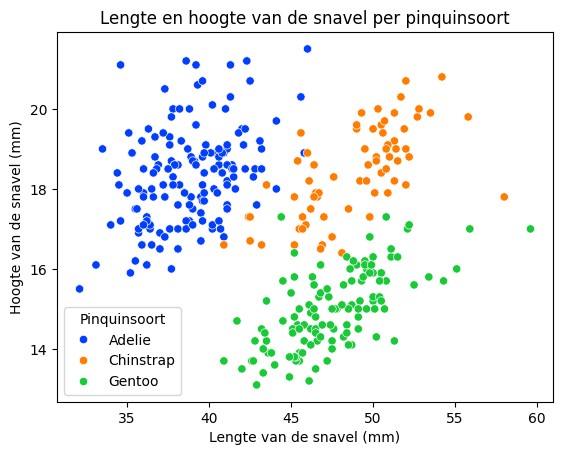

In [ ]:
sns.set_palette("bright")
ax = sns.scatterplot(x='culmen_length_mm',
                     y='culmen_depth_mm',
                     data=df,
                     hue='species')
plt.title('Lengte en hoogte van de snavel per pinquinsoort', color='black')
plt.xlabel('Lengte van de snavel (mm)')
plt.ylabel('Hoogte van de snavel (mm)')
plt.legend(title='Pinquinsoort')
plt.show()

In de scatterplot zien we duidelijke groepen van verschillende soorten pinguins met een bepaalde combinatie van lengte en hoogte ('diepte'). Deze 2 variabelen zouden een goed voorspellingsmodel kunnen maken.

## Hierarchische clustering
Er lijken 3 clusters te zijn. Dit is ook hierboven te zien. Inclusief enkele uitschieters kunnen we de scatterplots goed indelen per pinguinsoort.
<p>
Eens kijken of het dendrogram dit bevestigt:

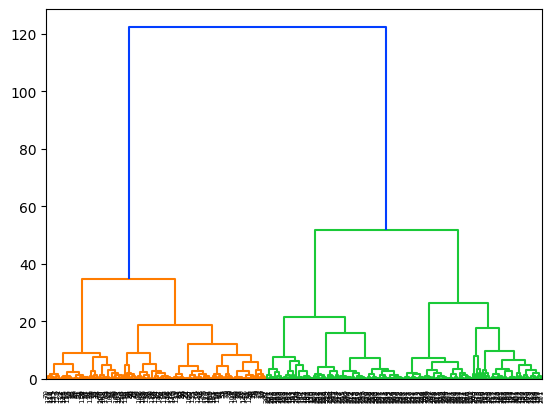

In [ ]:
data_gefilterd = df.loc[:, ["culmen_length_mm", "culmen_depth_mm"]]
data_gefilterd

linkage_data = linkage(data_gefilterd, method='ward', metric='euclidean')
dendrogram(linkage_data)
plt.show()

Zien we 3 clusters?
<p>
Eens kijken of de visualisatie hetzelfde resultaat geeft:

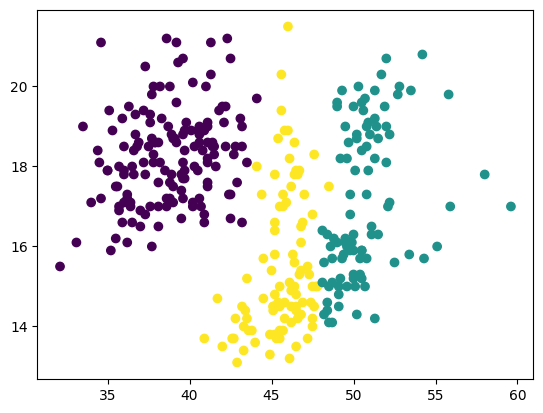

In [ ]:
data_gefilterd = df.loc[:, ["culmen_length_mm", "culmen_depth_mm"]]
data_gefilterd

x = df.loc[:, ["culmen_length_mm"]]
y = df.loc[:, ["culmen_depth_mm"]]

hierarchical_cluster = AgglomerativeClustering(n_clusters=3, metric='euclidean', linkage='ward')
labels = hierarchical_cluster.fit_predict(data_gefilterd)

plt.scatter(x,y, c=labels)
plt.show()

Conclusie?

# Voorbeeld 3 VU studentendataset
Nu kijken of we deze techniek kunnen toepassen op onze NUMERIEKE data.<br>

Eerst inlezen van een selectie (twee kolommen: income en bmi) van de data.

In [ ]:
df = pd.read_excel("vustudentanalytics.xlsx")
df['bmi_calc'] = df['weight'] / (df['height']/100)**2
df = df.loc[:, ["income", "bmi_calc"]]
df.head() # We take a look at the first 5 rows of the dataset

,income,bmi_calc
0,800.0,30.795848
1,350.0,23.449341
2,NaN,18.365473
3,900.0,30.468750
4,1500.0,20.028842


In [ ]:
df.shape

(5000, 2)

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 2 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   income    4317 non-null   float64
 1   bmi_calc  4947 non-null   float64
dtypes: float64(2)
memory usage: 78.3 KB


We zien dat er 5.000 regels in de dataset zitten, maar in zowel de income als de bmi-kolom ontbreken er waarden.<p>
Om hierarchische clustering uit te kunnen voeren, mogen er geen NULL of NaN waarden in de tabel zitten.<p>
Die gaan we dus eerst verwijderen.

In [ ]:
df_analyse = df.dropna()
df_analyse = df_analyse[df_analyse.income != -8]
df_analyse.info()

<class 'pandas.core.frame.DataFrame'>
Index: 3684 entries, 0 to 4998
Data columns (total 2 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   income    3684 non-null   float64
 1   bmi_calc  3684 non-null   float64
dtypes: float64(2)
memory usage: 86.3 KB


We houden 3.684 regels over, daarmee gaan we nu clusteren.<p>
Onze hypothese is dat er 3 clusters in de data zitten:<br>
- 1 cluster met laag inkomen, hoge bmi<br>
- 1 cluster met gemiddeld inkomen en gemiddelde bmi<br>
- 1 cluster met hoog inkomen en lage bmi

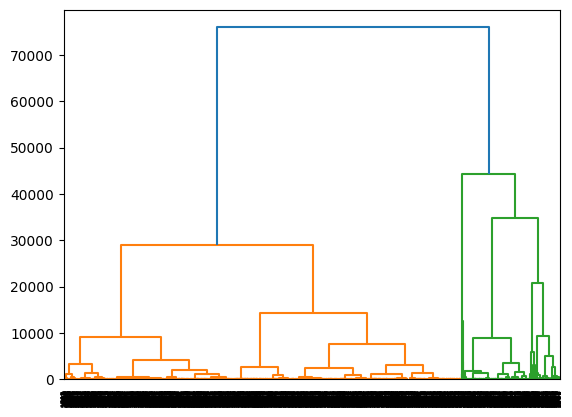

In [ ]:
linkage_data = linkage(df_analyse, method='ward', metric='euclidean')
dendrogram(linkage_data)
plt.show()

Hoeveel clusters zien we?

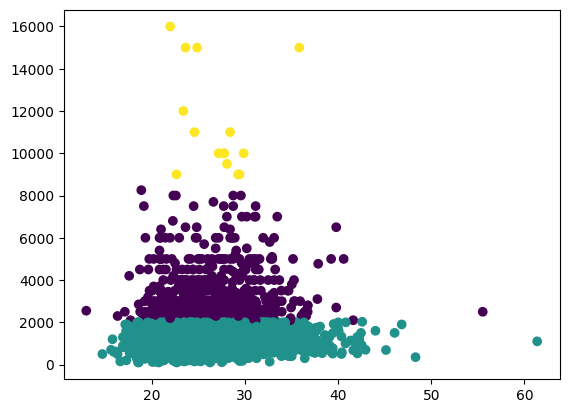

In [ ]:
x = df_analyse.loc[:, ["bmi_calc"]]
y = df_analyse.loc[:, ["income"]]

hierarchical_cluster = AgglomerativeClustering(n_clusters=3, metric='euclidean', linkage='ward')
labels = hierarchical_cluster.fit_predict(df_analyse)

plt.scatter(x,y, c=labels)
plt.show()

Grote Vraag: is dit nu zinvol? Hebben we iets aan deze clusteranalyse?

# Voorbeeld 4 Portfolio

In [ ]:
! pip install pandas-datareader==0.10.0
! pip install yfinance
! pip install --upgrade yfinance

import yfinance as yf
import pandas as pd
import pandas_datareader.data as web
import datetime as dt
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from datetime import date

#Clear output
from google.colab import output
output.clear()

In [ ]:
#yf.pdr_override()

start = dt.datetime(2018,5,1)
end = dt.datetime(2024,5,1)

apple = yf.download('AAPL', start, end).tz_localize(None) # Apple
shell = yf.download('SHEL', start, end).tz_localize(None) # Shell
ng = yf.download('NOC', start, end).tz_localize(None) # Northrop Grumman
tsm = yf.download('TSM', start, end).tz_localize(None) # Taiwan Semiconductor Manufacturing Company (TSMC)
rio = yf.download('RIO', start, end).tz_localize(None) # Rio Tinto Group
ge = yf.download('GE', start, end).tz_localize(None) # General Electric Company
gs = yf.download('GS', start, end).tz_localize(None) # The Goldman Sachs Group
bond = yf.download('BOND', start, end).tz_localize(None) # PIMCO Active Bond Exchange-Traded Fund
btc = yf.download('BTC-USD', start, end).tz_localize(None) # Bitcoin USD
xrp = yf.download('XRP-USD', start, end).tz_localize(None) # XRP USD

YF.download() has changed argument auto_adjust default to True


[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed


In [ ]:
portfolio = pd.concat([apple.add_suffix("_Apple"), shell.add_suffix("_Shell"), ng.add_suffix("_Northrop"),tsm.add_suffix("_TSMC"), rio.add_suffix("_RioTinto"), ge.add_suffix("_GE"), gs.add_suffix("_GoldmanSachs"), bond.add_suffix("_Bond"), btc.add_suffix("_Bitcoin"), xrp.add_suffix("_Ripple")], axis=1)
portfolio_gefilterd = portfolio.loc[:, ["Close_Apple", "Close_Shell", "Close_Northrop", "Close_TSMC","Close_RioTinto","Close_GE","Close_GoldmanSachs","Close_Bond","Close_Bitcoin","Close_Ripple"]]
portfolio_gefilterd.columns = ["Close_Apple", "Close_Shell", "Close_Northrop", "Close_TSMC","Close_RioTinto","Close_GE","Close_GoldmanSachs","Close_Bond","Close_Bitcoin","Close_Ripple"]
portfolio_gevuld = portfolio_gefilterd.ffill()
portfolio_gevuld

,Close_Apple,Close_Shell,Close_Northrop,Close_TSMC,Close_RioTinto,Close_GE,Close_GoldmanSachs,Close_Bond,Close_Bitcoin,Close_Ripple
Date,,,,,,,,,,
2018-05-01,39.847019,50.096245,273.995239,32.430241,29.978443,64.199776,201.957413,79.888031,9119.009766,0.841407
2018-05-02,41.607262,50.190571,273.941803,31.447250,30.231186,64.793770,199.721695,79.849121,9235.919922,0.859094
2018-05-03,41.682678,50.502544,281.540375,31.738806,30.472952,63.651428,199.175568,79.841354,9743.860352,0.884466
2018-05-04,43.318027,50.669399,279.908264,32.146996,30.560862,64.428223,200.481140,79.942528,9700.759766,0.895442
2018-05-05,43.318027,50.669399,279.908264,32.146996,30.560862,64.428223,200.481140,79.942528,9858.150391,0.905103
...,...,...,...,...,...,...,...,...,...,...
2024-04-26,168.283661,69.643875,472.327209,136.391876,63.981560,161.272690,418.341431,84.381561,63755.320312,0.526112
2024-04-27,168.283661,69.643875,472.327209,136.391876,63.981560,161.272690,418.341431,84.381561,63419.140625,0.517775
2024-04-28,168.283661,69.643875,472.327209,136.391876,63.981560,161.272690,418.341431,84.381561,63113.230469,0.510377


In [ ]:
graan = web.get_data_fred('PWHEAMTUSDM', start, end) #graan
hout = web.get_data_fred('WPU08', start, end) #hout
katoen = web.get_data_fred('PCOTTINDUSDM', start, end) #katoen
koffie = web.get_data_fred('WPU026301', start, end) #koffiebonen
rubber = web.get_data_fred('PRUBBUSDM', start, end) #rubber
vlees = web.get_data_fred('PBEEFUSDM', start, end) #vleesprijs
wol = web.get_data_fred('PWOOLFUSDM', start, end) #wol
zonnebloem = web.get_data_fred('PSUNOUSDM', start, end) #zonnebloemolie

gas = web.get_data_fred('GASREGW', start, end) #gas (US Regular All Formulations Gas Price)
kolen = web.get_data_fred('WPU058103', start, end) #kolen (Producer Price Index by Commodity: Fuels and Related Products and Power: Other Petroleum and Coal Products, Including Coke Oven Products, Not Elsewhere Classified)
oil = yf.download('CL=F', start, end).tz_localize(None) #olie
uranium = web.get_data_fred('PURANUSDM', start, end) #uranium

goud = yf.download('GC=F', start, end).tz_localize(None) #goud future
koper = web.get_data_fred('PCOPPUSDM', start, end) #koperprijs
palladium = yf.download('PA=F', start, end).tz_localize(None) #palladium
staal = web.get_data_fred('WPU101707', start, end) #staal (Producer Price Index by Commodity: Metals and Metal Products: Cold Rolled Steel Sheet and Strip )
zilver = yf.download('SI=F', start, end).tz_localize(None) #zilver future

#kobalt
#silicium

[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed


In [ ]:
grondstoffen_1 = pd.concat([graan, koffie, vlees, gas, kolen], axis=1)
grondstoffen_1.columns = ["Graan", "Koffie", "Vlees", "Gas", "Kolen"]
grondstoffen_1

,Graan,Koffie,Vlees,Gas,Kolen
DATE,,,,,
2018-05-01,192.70383,194.200,188.000000,NaN,595.400
2018-05-07,NaN,NaN,NaN,2.845,NaN
2018-05-14,NaN,NaN,NaN,2.873,NaN
2018-05-21,NaN,NaN,NaN,2.923,NaN
2018-05-28,NaN,NaN,NaN,2.962,NaN
...,...,...,...,...,...
2024-04-08,NaN,NaN,NaN,3.591,NaN
2024-04-15,NaN,NaN,NaN,3.628,NaN
2024-04-22,NaN,NaN,NaN,3.668,NaN


In [ ]:
grondstoffen_2 = pd.concat([oil.add_suffix("_Olie"), goud.add_suffix("_Goud"), palladium.add_suffix("_Palladium")], axis = 1)
grondstoffen_2 = grondstoffen_2.loc[:, ["Close_Olie", "Close_Goud", "Close_Palladium"]]
grondstoffen_2.columns = ["Olie", "Goud", "Palladium"]
grondstoffen_2

,Olie,Goud,Palladium
Date,,,
2018-05-01,67.250000,1303.800049,938.450012
2018-05-02,67.930000,1302.599976,962.349976
2018-05-03,68.430000,1310.699951,960.900024
2018-05-04,69.720001,1312.699951,959.450012
2018-05-07,70.730003,1312.199951,964.299988
...,...,...,...
2024-04-24,82.809998,2324.500000,1007.400024
2024-04-25,83.570000,2329.800049,981.099976
2024-04-26,83.849998,2334.800049,957.400024


In [ ]:
grondstoffen_portfolio = pd.concat([grondstoffen_1, grondstoffen_2], axis=1)
grondstoffen_portfolio = grondstoffen_portfolio.ffill()
grondstoffen_portfolio

,Graan,Koffie,Vlees,Gas,Kolen,Olie,Goud,Palladium
2018-05-01,192.703830,194.200,188.000000,NaN,595.400,67.250000,1303.800049,938.450012
2018-05-02,192.703830,194.200,188.000000,NaN,595.400,67.930000,1302.599976,962.349976
2018-05-03,192.703830,194.200,188.000000,NaN,595.400,68.430000,1310.699951,960.900024
2018-05-04,192.703830,194.200,188.000000,NaN,595.400,69.720001,1312.699951,959.450012
2018-05-07,192.703830,194.200,188.000000,2.845,595.400,70.730003,1312.199951,964.299988
...,...,...,...,...,...,...,...,...
2024-04-25,208.381685,253.486,270.568182,3.668,638.273,83.570000,2329.800049,981.099976
2024-04-26,208.381685,253.486,270.568182,3.668,638.273,83.849998,2334.800049,957.400024
2024-04-29,208.381685,253.486,270.568182,3.653,638.273,82.629997,2345.399902,976.700012
2024-04-30,208.381685,253.486,270.568182,3.653,638.273,81.930000,2291.399902,951.900024


In [ ]:
portfolio_compleet = pd.concat([portfolio_gevuld, grondstoffen_portfolio], axis=1)
portfolio_compleet = portfolio_compleet.ffill()
portfolio_compleet = portfolio_compleet.loc[portfolio_compleet.loc[:, "Gas"] > 0, :]
portfolio_compleet

,Close_Apple,Close_Shell,Close_Northrop,Close_TSMC,Close_RioTinto,Close_GE,Close_GoldmanSachs,Close_Bond,Close_Bitcoin,Close_Ripple,Graan,Koffie,Vlees,Gas,Kolen,Olie,Goud,Palladium
2018-05-07,43.631428,50.589596,282.833557,32.030376,30.483940,64.291153,202.409637,79.950325,9373.009766,0.832641,192.703830,194.200,188.000000,2.845,595.400,70.730003,1312.199951,964.299988
2018-05-08,43.841152,50.807240,293.660706,32.638493,30.445475,65.205025,202.239014,79.849121,9234.820312,0.813970,192.703830,194.200,188.000000,2.845,595.400,69.059998,1312.000000,965.599976
2018-05-09,44.149837,52.026104,292.162415,32.780113,31.077358,66.804291,206.275223,79.732384,9325.179688,0.802043,192.703830,194.200,188.000000,2.845,595.400,71.139999,1311.300049,972.799988
2018-05-10,44.781368,52.217236,291.109955,33.129986,31.511419,67.124176,207.734451,79.825813,9043.940430,0.758237,192.703830,194.200,188.000000,2.845,595.400,71.360001,1320.800049,996.099976
2018-05-11,44.611038,52.922981,290.119995,33.246613,31.533403,66.712921,207.290726,79.926979,8441.490234,0.684948,192.703830,194.200,188.000000,2.845,595.400,70.699997,1319.000000,987.400024
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2024-04-27,168.283661,69.643875,472.327209,136.391876,63.981560,161.272690,418.341431,84.381561,63419.140625,0.517775,208.381685,253.486,270.568182,3.668,638.273,83.849998,2334.800049,957.400024
2024-04-28,168.283661,69.643875,472.327209,136.391876,63.981560,161.272690,418.341431,84.381561,63113.230469,0.510377,208.381685,253.486,270.568182,3.668,638.273,83.849998,2334.800049,957.400024
2024-04-29,172.458450,69.501305,477.999634,136.589111,64.703506,163.398483,421.511475,84.712952,63841.121094,0.515432,208.381685,253.486,270.568182,3.653,638.273,82.629997,2345.399902,976.700012
2024-04-30,169.307480,68.113548,476.829742,135.445099,63.597149,160.746185,417.499969,84.438362,60636.855469,0.500065,208.381685,253.486,270.568182,3.653,638.273,81.930000,2291.399902,951.900024


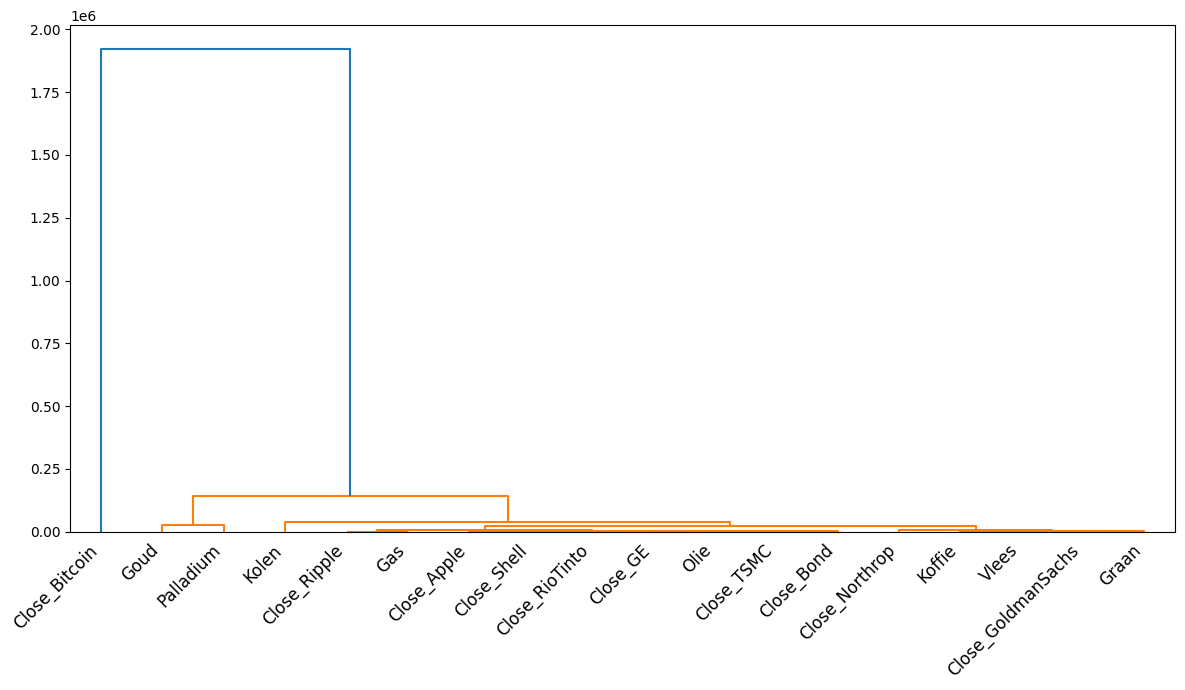

In [ ]:
# Apply linkage to the transpose of the DataFrame to cluster the columns (assets/commodities)
linkage_data = linkage(portfolio_compleet.T, method='ward', metric='euclidean')

# Create a figure and axes with a specific size
# Adjust the figsize tuple (width, height) as needed to make labels readable
plt.figure(figsize=(12, 7)) # Example size, you might need to experiment

# Plot the dendrogram with the column names as labels
dendrogram(linkage_data, labels=portfolio_compleet.columns)

# Optional: Rotate the x-axis labels if they are still overlapping
plt.xticks(rotation=45, ha='right')
plt.tight_layout() # Adjust layout to prevent labels from being cut off

plt.show()

Conclusie?

Index(['Close_Apple', 'Close_Shell', 'Close_Northrop', 'Close_TSMC',
       'Close_RioTinto', 'Close_GE', 'Close_GoldmanSachs', 'Close_Bond',
       'Close_Bitcoin', 'Close_Ripple', 'Graan', 'Koffie', 'Vlees', 'Gas',
       'Kolen', 'Olie', 'Goud', 'Palladium'],
      dtype='object')


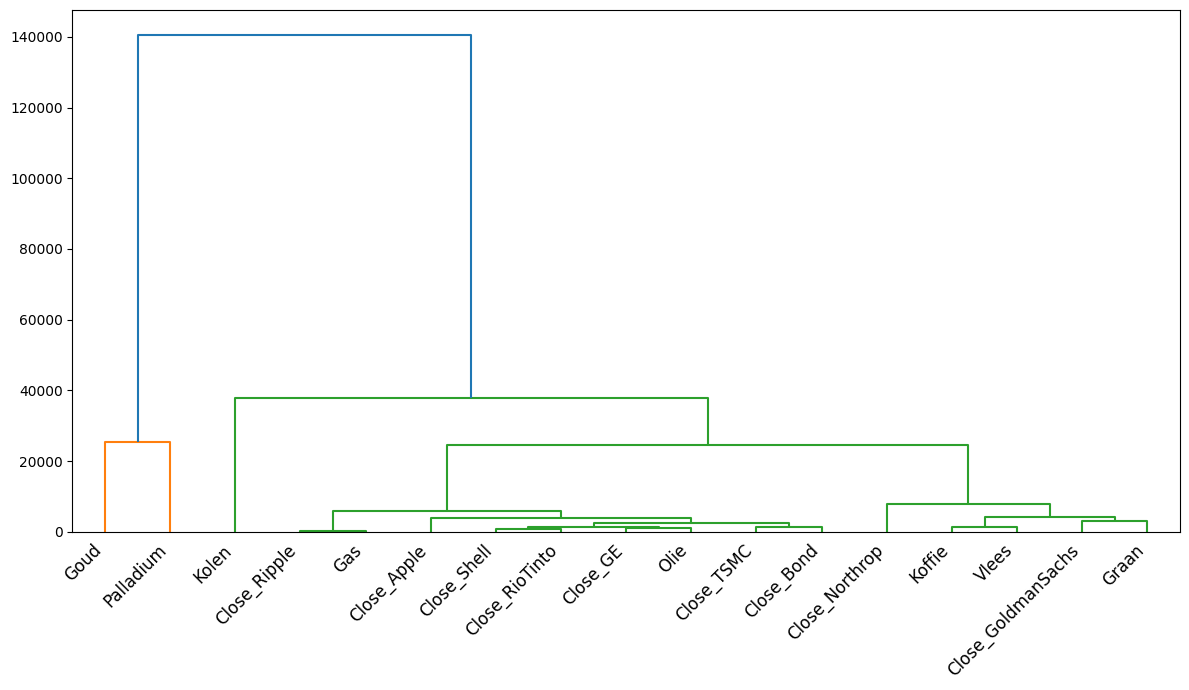

In [ ]:
# Select the data excluding Bitcoin
# Drop the column before filtering to ensure it exists

# Print the columns to verify the name
print(portfolio_compleet.columns)

# Assuming the column exists and the name is correct, proceed with dropping
# If the name is different, use the correct name
portfolio_without_bitcoin = portfolio_compleet.drop(columns=['Close_Bitcoin'])

# Ensure all column names are strings for the dendrogram labels
portfolio_without_bitcoin.columns = portfolio_without_bitcoin.columns.astype(str)

# Apply linkage to the transpose of the DataFrame without Bitcoin
linkage_data_without_bitcoin = linkage(portfolio_without_bitcoin.T, method='ward', metric='euclidean')

# Create a figure and axes with a specific size
# Adjust the figsize tuple (width, height) as needed to make labels readable
plt.figure(figsize=(12, 7)) # Example size, you might need to experiment

# Plot the dendrogram with the column names as labels
dendrogram(linkage_data_without_bitcoin, labels=portfolio_without_bitcoin.columns)

# Optional: Rotate the x-axis labels if they are still overlapping
plt.xticks(rotation=45, ha='right')
plt.tight_layout() # Adjust layout to prevent labels from being cut off

plt.show()

Conclusie?

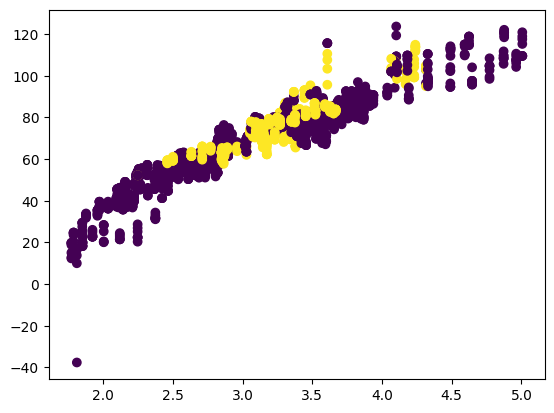

In [ ]:
x = portfolio_compleet.loc[:, ["Gas"]]
y = portfolio_compleet.loc[:, ["Olie"]]

# Ensure all column names are strings
portfolio_compleet.columns = portfolio_compleet.columns.astype(str)

hierarchical_cluster = AgglomerativeClustering(n_clusters=2, metric='euclidean', linkage='ward')
labels = hierarchical_cluster.fit_predict(portfolio_compleet)

plt.scatter(x,y, c=labels)
plt.show()

The code plots "Gas" on the x-axis and "Olie" (Oil) on the y-axis from the portfolio_compleet dataframe. The points are colored based on the results of a hierarchical clustering with 2 clusters (n_clusters=2).

Therefore, this scatterplot shows the relationship between the price of Gas and the price of Oil, with the data points colored to indicate which of the two clusters each observation belongs to according to the clustering algorithm.

To interpret the scatterplot, you would look for visual separation between the points of different colors. This would indicate whether the clustering algorithm found distinct groups in the Gas and Oil price data.

## Which metric to use with linkage

In this notebook, we are using metric='euclidean' with the linkage function. This is a very common choice and is the standard Euclidean distance between data points.

The linkage function calculates distances between data points or clusters based on a specified metric. You can choose from a variety of distance metrics. Some other common metrics include:

<b>'cityblock' (Manhattan distance):</b> The sum of the absolute differences between the coordinates of the two points.<br>
<b>'cosine':</b> Measures the cosine of the angle between two vectors. This is useful when the magnitude of the data points is not as important as their direction.<br>
<b>'correlation':</b> Measures the Pearson correlation coefficient between two vectors. This can be useful when you want to cluster items that have similar patterns over time or across features.
<p>
The best metric to use depends on the nature of your data and the kind of relationships you want to capture in your clusters. For instance, if your data has a clear geometric interpretation, Euclidean distance is often a good choice. If you are dealing with time series data or data where the relationships are more about trends than absolute values, correlation distance might be more appropriate.

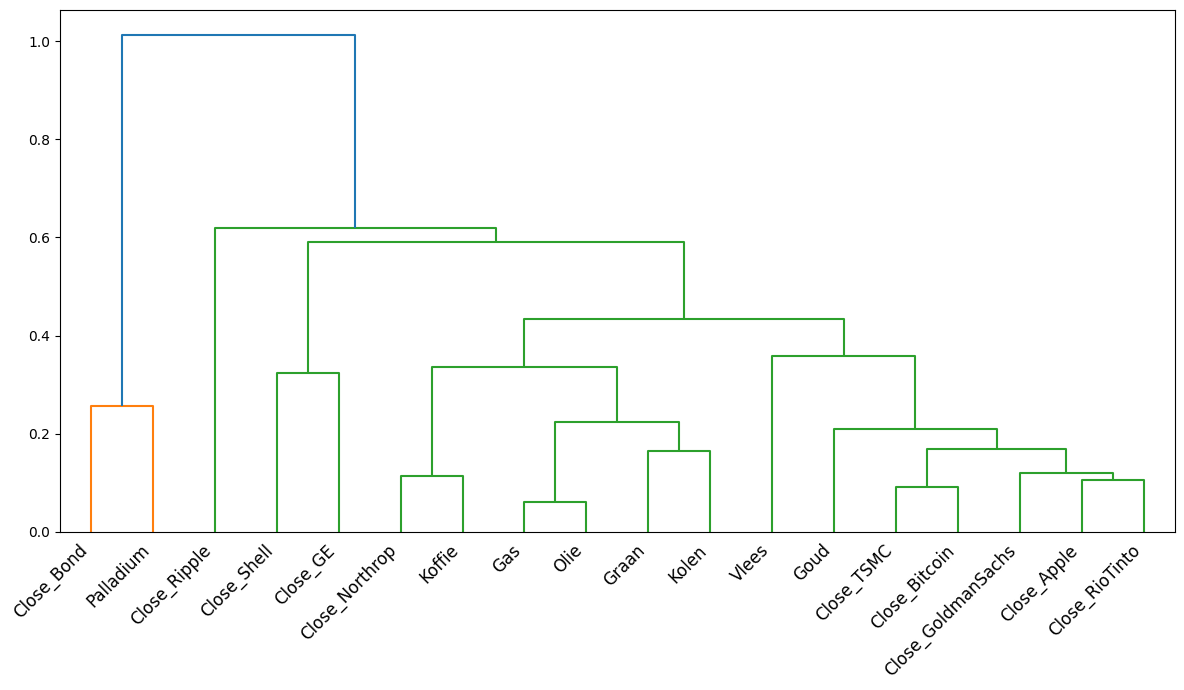

In [ ]:
# Apply linkage to the transpose of the DataFrame to cluster the columns (assets/commodities)
linkage_data = linkage(portfolio_compleet.T, method='average', metric='correlation')

# Create a figure and axes with a specific size
# Adjust the figsize tuple (width, height) as needed to make labels readable
plt.figure(figsize=(12, 7)) # Example size, you might need to experiment

# Plot the dendrogram with the column names as labels
dendrogram(linkage_data, labels=portfolio_compleet.columns)

# Optional: Rotate the x-axis labels if they are still overlapping
plt.xticks(rotation=45, ha='right')
plt.tight_layout() # Adjust layout to prevent labels from being cut off

plt.show()

## Which method to use with linkage

<b>'ward':</b> This method minimizes the variance of the clusters being merged. It is generally considered a good all-around method and is often the default choice. It tends to produce compact, spherical clusters.<br>
<b>'average':</b> This method calculates the average distance between all pairs of data points in the two clusters being merged.<br>
<b>'complete':</b> This method calculates the maximum distance between any two data points in the two clusters being merged (the "farthest neighbor"). This method can be sensitive to outliers.<br>
<b>'single':</b> This method calculates the minimum distance between any two data points in the two clusters being merged (the "nearest neighbor"). This method can sometimes result in "chaining," where clusters are joined based on single close points, leading to elongated clusters.
<p>
The best method to use depends on the structure of your data and the type of clusters you expect to find. 'ward' is a good starting point, but it's often beneficial to experiment with other methods like 'average' and 'complete' to see how they affect the resulting dendrogram and clusters.